<a href="https://colab.research.google.com/github/Abhyuday-19/stock-prediction-model/blob/main/Stock_LSTM_Attention_Transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q yfinance

import numpy as np
import pandas as pd
import yfinance as yf
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [ ]:
TICKER = "RELIANCE.NS"   # yahan apna pasand ka stock daal sakte ho
START = "2018-01-01"
END = "2026-10-01"

df = yf.download(TICKER, start=START, end=END)
df = df[["Close"]].dropna()
print(df.shape)
df.tail()

/tmp/ipykernel_1392/3849614286.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(TICKER, start=START, end=END)
[*********************100%***********************]  1 of 1 completed

(2161, 1)


Price,Close
Ticker,RELIANCE.NS
Date,
2026-09-24,1219.199951
2026-09-25,1226.000000
2026-09-28,1197.599976
2026-09-29,1182.000000
2026-09-30,1187.000000


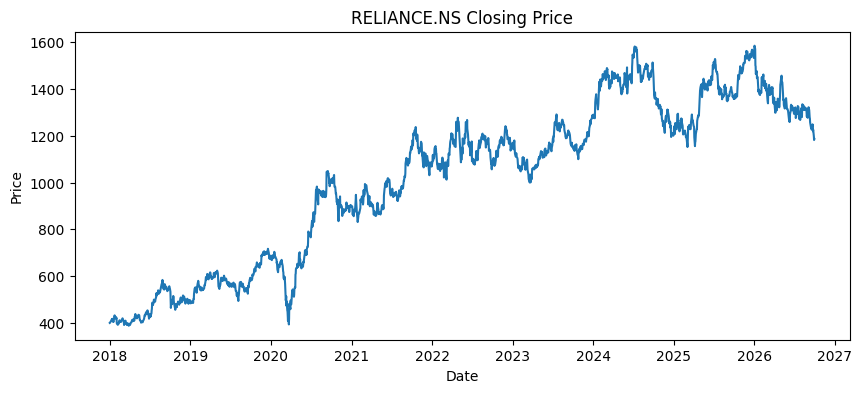

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["Close"])
plt.title(f"{TICKER} Closing Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()

In [ ]:
WINDOW = 60   # pichle 60 din ka data dekh ke agle din predict karenge

values = df["Close"].values.reshape(-1, 1).astype("float32")

data_min, data_max = values.min(), values.max()
scaled = (values - data_min) / (data_max - data_min)

def create_sequences(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window:i])
        y.append(data[i])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled, WINDOW)
print("X shape:", X.shape, "y shape:", y.shape)

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.float32).to(device)
X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.float32).to(device)

print("Train:", X_train_t.shape, " Test:", X_test_t.shape)

X shape: (2101, 60, 1) y shape: (2101, 1)
Train: torch.Size([1680, 60, 1])  Test: torch.Size([421, 60, 1])


In [ ]:
class PlainLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = out[:, -1, :]        # (batch, hidden)
        return self.fc(last_hidden)

In [ ]:
class Attention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.attn = nn.Linear(hidden_size, 1)   # score for each time step

    def forward(self, lstm_out):
        # lstm_out: (batch, seq_len, hidden)
        scores = self.attn(lstm_out).squeeze(-1)        # (batch, seq_len)
        weights = torch.softmax(scores, dim=1)           # (batch, seq_len) sums to 1
        context = torch.bmm(weights.unsqueeze(1), lstm_out).squeeze(1)  # (batch, hidden)
        return context, weights


class LSTMAttention(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.attention = Attention(hidden_size)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x, return_attention=False):
        lstm_out, _ = self.lstm(x)                       # (batch, seq_len, hidden)
        context, weights = self.attention(lstm_out)
        out = self.fc(context)
        if return_attention:
            return out, weights
        return out

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))   # (1, max_len, d_model)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TransformerTimeSeries(nn.Module):
    def __init__(self, input_size=1, d_model=64, nhead=4, num_layers=2, dim_feedforward=128):
        super().__init__()
        self.input_proj = nn.Linear(input_size, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            batch_first=True, dropout=0.1,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        x = self.input_proj(x)             # (batch, seq_len, d_model)
        x = self.pos_encoder(x)
        out = self.encoder(x)               # (batch, seq_len, d_model)
        pooled = out.mean(dim=1)            # average pooling over time
        return self.fc(pooled)

In [ ]:
def train_model(model, X_train, y_train, X_test, y_test, epochs=60, lr=1e-3, batch_size=32):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    n = X_train.shape[0]
    history = {"train_loss": [], "test_loss": []}

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_train[idx], y_train[idx]

            optimizer.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * xb.size(0)

        train_loss = epoch_loss / n

        model.eval()
        with torch.no_grad():
            test_pred = model(X_test)
            test_loss = loss_fn(test_pred, y_test).item()

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d}/{epochs} | train_loss {train_loss:.6f} | test_loss {test_loss:.6f}")

    return history

In [ ]:
print("Training Plain LSTM...")
lstm_model = PlainLSTM()
lstm_history = train_model(lstm_model, X_train_t, y_train_t, X_test_t, y_test_t)

print("\nTraining LSTM + Attention...")
attn_model = LSTMAttention()
attn_history = train_model(attn_model, X_train_t, y_train_t, X_test_t, y_test_t)

print("\nTraining Transformer...")
transformer_model = TransformerTimeSeries()
trans_history = train_model(transformer_model, X_train_t, y_train_t, X_test_t, y_test_t)

Training Plain LSTM...
Epoch   1/60 | train_loss 0.065470 | test_loss 0.022357
Epoch  10/60 | train_loss 0.000592 | test_loss 0.001051
Epoch  20/60 | train_loss 0.000517 | test_loss 0.000797
Epoch  30/60 | train_loss 0.000516 | test_loss 0.000765
Epoch  40/60 | train_loss 0.000375 | test_loss 0.000835
Epoch  50/60 | train_loss 0.000315 | test_loss 0.000430
Epoch  60/60 | train_loss 0.000292 | test_loss 0.000385

Training LSTM + Attention...
Epoch   1/60 | train_loss 0.055757 | test_loss 0.010258
Epoch  10/60 | train_loss 0.003623 | test_loss 0.003548
Epoch  20/60 | train_loss 0.003429 | test_loss 0.003820
Epoch  30/60 | train_loss 0.002888 | test_loss 0.003330
Epoch  40/60 | train_loss 0.002295 | test_loss 0.002418
Epoch  50/60 | train_loss 0.001091 | test_loss 0.001410
Epoch  60/60 | train_loss 0.000622 | test_loss 0.000665

Training Transformer...
Epoch   1/60 | train_loss 0.035931 | test_loss 0.003215
Epoch  10/60 | train_loss 0.000518 | test_loss 0.000444
Epoch  20/60 | train_loss 

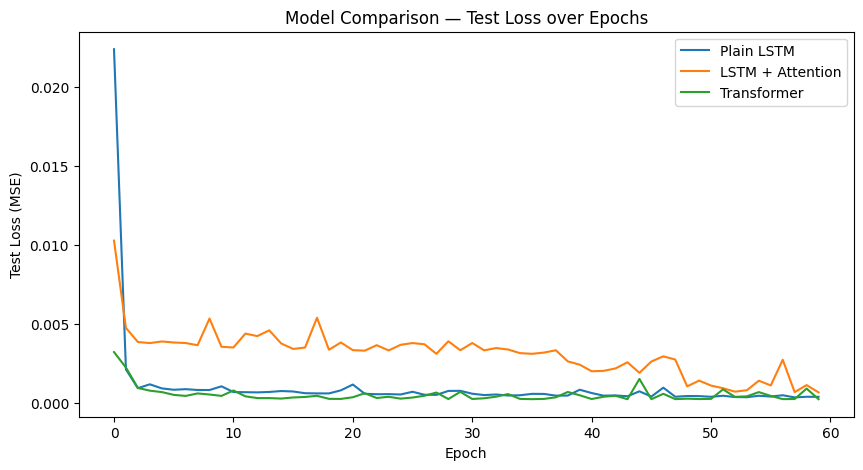

Final test loss:
  Plain LSTM       : 0.000385
  LSTM + Attention : 0.000665
  Transformer      : 0.000237


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(lstm_history["test_loss"], label="Plain LSTM")
plt.plot(attn_history["test_loss"], label="LSTM + Attention")
plt.plot(trans_history["test_loss"], label="Transformer")
plt.xlabel("Epoch")
plt.ylabel("Test Loss (MSE)")
plt.title("Model Comparison — Test Loss over Epochs")
plt.legend()
plt.show()

print("Final test loss:")
print(f"  Plain LSTM       : {lstm_history['test_loss'][-1]:.6f}")
print(f"  LSTM + Attention : {attn_history['test_loss'][-1]:.6f}")
print(f"  Transformer      : {trans_history['test_loss'][-1]:.6f}")

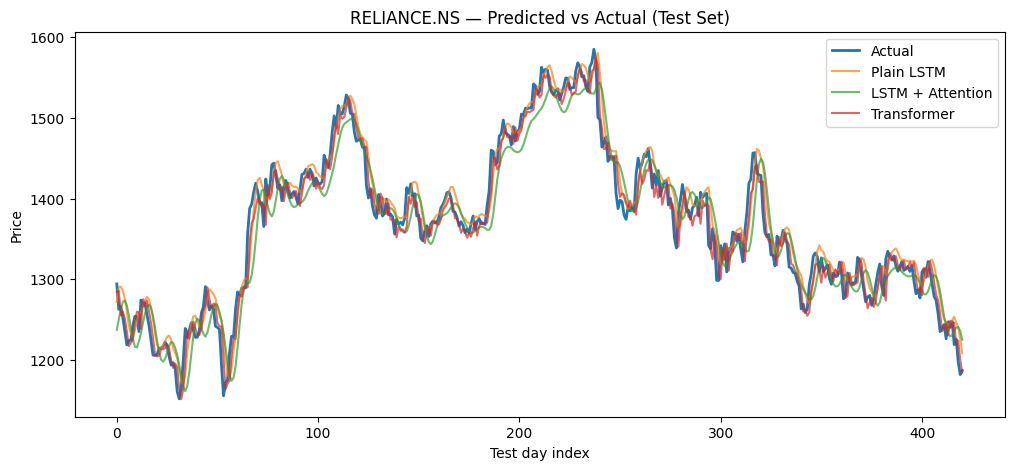

In [ ]:
def inverse_scale(arr):
    return arr * (data_max - data_min) + data_min

with torch.no_grad():
    lstm_pred = inverse_scale(lstm_model(X_test_t).cpu().numpy())
    attn_pred = inverse_scale(attn_model(X_test_t).cpu().numpy())
    trans_pred = inverse_scale(transformer_model(X_test_t).cpu().numpy())

actual = inverse_scale(y_test_t.cpu().numpy())

plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual", linewidth=2)
plt.plot(lstm_pred, label="Plain LSTM", alpha=0.7)
plt.plot(attn_pred, label="LSTM + Attention", alpha=0.7)
plt.plot(trans_pred, label="Transformer", alpha=0.7)
plt.title(f"{TICKER} — Predicted vs Actual (Test Set)")
plt.xlabel("Test day index")
plt.ylabel("Price")
plt.legend()
plt.show()

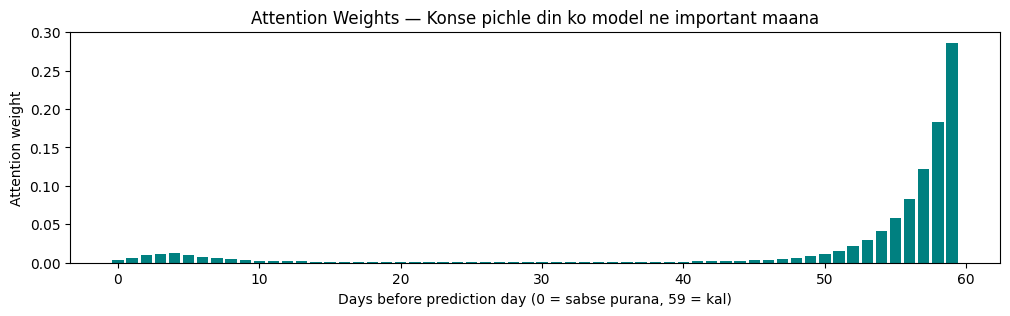

Sabse zyada attention diya din #59 ko (ie 1 din pehle), weight = 0.2863


In [ ]:
attn_model.eval()
with torch.no_grad():
    sample_idx = 0
    sample_x = X_test_t[sample_idx:sample_idx + 1]     # ek test example
    _, weights = attn_model(sample_x, return_attention=True)
    weights = weights.cpu().numpy().flatten()           # (WINDOW,)

plt.figure(figsize=(12, 3))
plt.bar(range(WINDOW), weights, color="teal")
plt.title("Attention Weights — Konse pichle din ko model ne important maana")
plt.xlabel("Days before prediction day (0 = sabse purana, 59 = kal)")
plt.ylabel("Attention weight")
plt.show()

print(f"Sabse zyada attention diya din #{weights.argmax()} ko "
      f"(ie {WINDOW - weights.argmax()} din pehle), weight = {weights.max():.4f}")

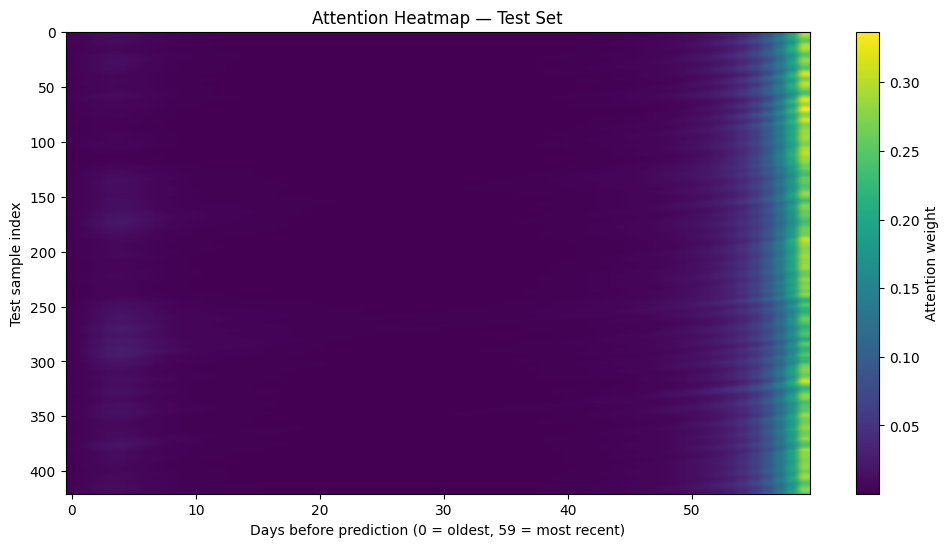

In [ ]:
attn_model.eval()
with torch.no_grad():
    _, all_weights = attn_model(X_test_t, return_attention=True)
    all_weights = all_weights.cpu().numpy()     # (num_test, WINDOW)

plt.figure(figsize=(12, 6))
plt.imshow(all_weights, aspect="auto", cmap="viridis")
plt.colorbar(label="Attention weight")
plt.xlabel("Days before prediction (0 = oldest, 59 = most recent)")
plt.ylabel("Test sample index")
plt.title("Attention Heatmap — Test Set")
plt.show()